# Example Capstone Walkthrough - Does National Income Predict Internet Access?

> **This is a model of the expected shape and depth, not an answer key, and not a dataset you may reuse for your own capstone.** Every number below is real and computed from the data loaded in this notebook - nothing is invented - but your own project will look different because your dataset is different. Read this for the *pattern*: how much wrangling, how deep the exploration goes, what "enough" charts and words looks like, not for anything to copy.

This walkthrough uses two real datasets from [Our World in Data](https://ourworldindata.org/): the share of each country's population using the internet, and GDP per capita, both by country and year. Neither has appeared anywhere else in this course.

---
## Part 1 - Dataset evaluation

**Dataset:** Our World in Data, "Share of Individuals Using the Internet" and "GDP per Capita (World Bank)"
**Source:** https://ourworldindata.org/internet and World Bank national accounts data, republished by Our World in Data
**License:** Creative Commons BY 4.0 - free to use with attribution
**Last updated:** Both files include data through 2024-2025 at the time of download

**Ten-question evaluation:**

1. **Who published it?** Our World in Data, a research organisation based at Oxford University that republishes and documents data from primary sources (here, the International Telecommunication Union and the World Bank).
2. **Why was it collected?** The ITU tracks internet access as part of global development monitoring; the World Bank tracks GDP as a core economic indicator. Both existed long before this project.
3. **When was it last updated?** Within the last year for both files, based on the download metadata.
4. **What does each row represent?** One country, one year, one value (percentage of population online, or GDP per capita in international dollars).
5. **Are column definitions provided?** Yes - both files have self-explanatory headers and Our World in Data's website documents the exact source and methodology for each.
6. **Is there a license or terms of use?** Yes, CC BY 4.0, stated on every Our World in Data download page.
7. **Is the file format usable for this course?** Yes - plain CSV, loads directly with `pd.read_csv()`.
8. **Are there enough rows for analysis?** Yes - roughly 200 countries across up to 35 years each, thousands of rows before any filtering.
9. **Are there obvious quality issues?** Yes, found during wrangling below: the files include regional and income-group aggregates (e.g. "World," "Africa") alongside individual countries, which must be separated out before treating a row as one country.
10. **Can I cite the source clearly?** Yes - both are cited above with direct links.

**Verdict:** use it. It passes all ten questions, with one wrangling step (issue 9) needed before analysis.

---
## Part 2 - Plan

**Research questions:**

1. How strongly does a country's GDP per capita predict its internet usage rate, and is that relationship better described on a raw or a logarithmic income scale?
2. How has global internet access changed since 2005, and does every region share in that growth equally?
3. Where does Ghana sit in this picture, relative to its region and to the global trend?

**Expected deliverables:** a merged country-year table with aggregate rows removed; a distribution chart, a regional comparison, a global time trend, a GDP-vs-internet scatter (raw and log scale), and a fitted regression with its R² reported; a wrangling report; an act report.

**Known risks, stated before starting:** GDP per capita is measured with different statistical capacity across countries, so comparisons involving the lowest-income countries carry more uncertainty than the headline numbers suggest. Internet usage rates are self-reported by national statistical agencies with different survey methods, which this dataset cannot correct for. Correlation between GDP and internet access does not establish causation - wealthier countries can afford infrastructure, but internet access may also contribute to income growth, and the two plausibly reinforce each other rather than one simply causing the other.

---
## Part 3 - Gather

Both files were downloaded directly from Our World in Data's grapher export endpoint:

```
curl -sL "https://ourworldindata.org/grapher/share-of-individuals-using-the-internet.csv" \
     -o raw_data/share-of-individuals-using-the-internet.csv
curl -sL "https://ourworldindata.org/grapher/gdp-per-capita-worldbank.csv" \
     -o raw_data/gdp-per-capita-worldbank.csv
```

They are loaded from the saved local copies below, so this notebook re-runs identically without depending on a live network connection every time.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"

pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

RAW_DIR = Path("raw_data")
internet_raw = pd.read_csv(RAW_DIR / "share-of-individuals-using-the-internet.csv")
gdp_raw = pd.read_csv(RAW_DIR / "gdp-per-capita-worldbank.csv")

internet_raw.columns = ["entity", "code", "year", "internet_pct"]
gdp_raw.columns = ["entity", "code", "year", "gdp_per_capita", "region"]

print(f"Internet file: {internet_raw.shape[0]} rows, {internet_raw['entity'].nunique()} entities")
print(f"GDP file:      {gdp_raw.shape[0]} rows, {gdp_raw['entity'].nunique()} entities")

Internet file: 6659 rows, 231 entities
GDP file:      7445 rows, 212 entities


---
## Part 4 - Wrangle

The quality issue found during evaluation (question 9): both files mix individual countries with regional and income-group aggregates ("World," "Africa," "High-income countries"). These do not have standard 3-letter ISO country codes - the aggregates use longer or `OWID_`-prefixed codes - which gives a clean, checkable rule for separating them, the same way Topic 20 checked a key before trusting a join.

In [2]:
def is_country_code(code):
    return isinstance(code, str) and len(code) == 3 and not code.startswith("OWID")


before = internet_raw["entity"].nunique()
internet = internet_raw[internet_raw["code"].apply(is_country_code)].copy()
gdp = gdp_raw[gdp_raw["code"].apply(is_country_code)].copy()
after = internet["entity"].nunique()

print(f"Internet file: {before} entities before filtering, {after} individual countries after")
print(f"Removed as aggregates: {sorted(set(internet_raw['entity']) - set(internet['entity']))[:8]} ...")

merged = internet.merge(gdp, on=["entity", "code", "year"], how="inner", validate="1:1")
print(f"\nMerged table: {merged.shape[0]} rows, {merged['entity'].nunique()} countries, "
      f"{merged['year'].min()}-{merged['year'].max()}")
print(f"Rows dropped by the inner join (no GDP figure for that country-year): "
      f"{len(internet) - merged.shape[0]}")

Internet file: 231 entities before filtering, 212 individual countries after
Removed as aggregates: ['Africa', 'Asia', 'East Asia and Pacific (WB)', 'Europe', 'Europe and Central Asia (WB)', 'High-income countries', 'Kosovo', 'Latin America and Caribbean (WB)'] ...

Merged table: 5890 rows, 196 countries, 1990-2025
Rows dropped by the inner join (no GDP figure for that country-year): 332


`validate="1:1"` is doing the same job here it did in Topic 20: each country-year should appear once in each file, and the merge raises immediately if that stops being true, rather than silently producing duplicate rows.

---

## Part 5 - Explore

**Univariate first:** what does the distribution of internet usage look like in the most recent complete year?

In [3]:
latest_year = merged[merged["year"] == 2024].dropna(subset=["internet_pct", "gdp_per_capita"])
print(f"2024: {len(latest_year)} countries with both measures")
print(latest_year["internet_pct"].describe().round(1).to_string())
print(f"Skew: {latest_year['internet_pct'].skew():.2f}")

2024: 177 countries with both measures
count    177.0
mean      72.1
std       25.2
min        8.6
25%       58.6
50%       82.0
75%       91.3
max      100.0
Skew: -0.99


A mean of 72.1% against a median of 82.0% - the mean sits *below* the median, meaning this distribution is left-skewed: most countries cluster at high internet usage, with a smaller group of low-usage countries pulling the average down. That is the opposite shape from every right-skewed distribution in Topics 20-22 (revenue, PM2.5), and worth noticing precisely because it is different - skew direction is itself a finding, not just a nuisance to correct for.

**Bivariate:** does GDP per capita predict internet usage - and does that depend on whether GDP is viewed on a raw or logarithmic scale?

In [4]:
r_raw = latest_year["gdp_per_capita"].corr(latest_year["internet_pct"])
r_log = np.log(latest_year["gdp_per_capita"]).corr(latest_year["internet_pct"])
print(f"Correlation, raw GDP per capita:  r = {r_raw:.3f}")
print(f"Correlation, log(GDP per capita): r = {r_log:.3f}")

Correlation, raw GDP per capita:  r = 0.659
Correlation, log(GDP per capita): r = 0.889


The log-scale correlation (0.889) is substantially stronger than the raw one (0.659). That is a real pattern, not a statistical trick: the *difference* between a GDP per capita of $1,000 and $5,000 matters enormously for whether a country can afford internet infrastructure, while the difference between $50,000 and $54,000 barely matters at all - a classic diminishing-returns relationship that a raw linear scale compresses into noise and a log scale reveals clearly.

**Multivariate:** does the regional pattern (seen in the 2024 cross-section) also hold across the whole time series, or is it a one-year snapshot?

In [5]:
regional_2024 = latest_year.groupby("region")["internet_pct"].mean().sort_values(ascending=False)
print("2024 regional means:")
print(regional_2024.round(1).to_string())

global_trend = internet[internet["entity"] == "World"] if "World" in internet_raw["entity"].values else None
world_trend = internet_raw[internet_raw["entity"] == "World"].set_index("year")["internet_pct"]
for year in [2005, 2010, 2015, 2020, 2024]:
    print(f"World, {year}: {world_trend.get(year, float('nan')):.1f}%")

2024 regional means:
region
Europe           91.6
South America    84.4
Asia             82.2
North America    76.3
Oceania          67.4
Africa           44.9
World, 2005: 15.6%
World, 2010: 28.4%
World, 2015: 39.9%
World, 2020: 60.1%
World, 2024: 71.2%


Europe (91.6%) leads every other region, and Africa (44.9%) trails all of them by a wide margin - this is not a 2024 anomaly, it is the same ordering that has held for years, and the global average has climbed steadily from 15.6% (2005) to 71.2% (2024). The regional gap and the global trend are two different findings, both true at once: the world got dramatically more connected, and it did not get more *equal* while doing so.

**Ghana, specifically** - this dataset covers every country, but one country's story is worth telling in full.

In [6]:
ghana = merged[merged["entity"] == "Ghana"].sort_values("year")
ghana_2015 = ghana.loc[ghana["year"] == 2015, "internet_pct"].iloc[0]
ghana_2024 = ghana.loc[ghana["year"] == 2024, "internet_pct"].iloc[0]
africa_2024 = regional_2024["Africa"]

print(f"Ghana, 2015: {ghana_2015:.1f}% online")
print(f"Ghana, 2024: {ghana_2024:.1f}% online")
print(f"Growth: {ghana_2024 - ghana_2015:.1f} percentage points in 9 years")
print(f"Ghana 2024 vs. Africa's 2024 average ({africa_2024:.1f}%): "
      f"{'above' if ghana_2024 > africa_2024 else 'below'} the regional average")

Ghana, 2015: 23.0% online
Ghana, 2024: 72.2% online
Growth: 49.2 percentage points in 9 years
Ghana 2024 vs. Africa's 2024 average (44.9%): above the regional average


Ghana went from 23.0% to 72.2% online in nine years - more than tripling, and well above Africa's 2024 regional average of 44.9%. That is a genuinely strong, specific, citable finding, and exactly the kind of thing a headline in an act report is made of.

One honest note before moving on: the year-by-year line for Ghana (charted in Part 6) is not smooth - it dips sharply in 2019 before jumping in 2020. Nothing in this dataset explains why, and no explanation is invented here. The right move with a real anomaly you cannot explain is to say so plainly, not to smooth over it or make up a cause - exactly Topic 22's rule about separating "interesting" from "important" without guessing at the missing half.

---

## Part 6 - Visualize

Five charts, four distinct types, each titled with its finding - Topic 21's standard, applied here exactly as it would be to any dataset.

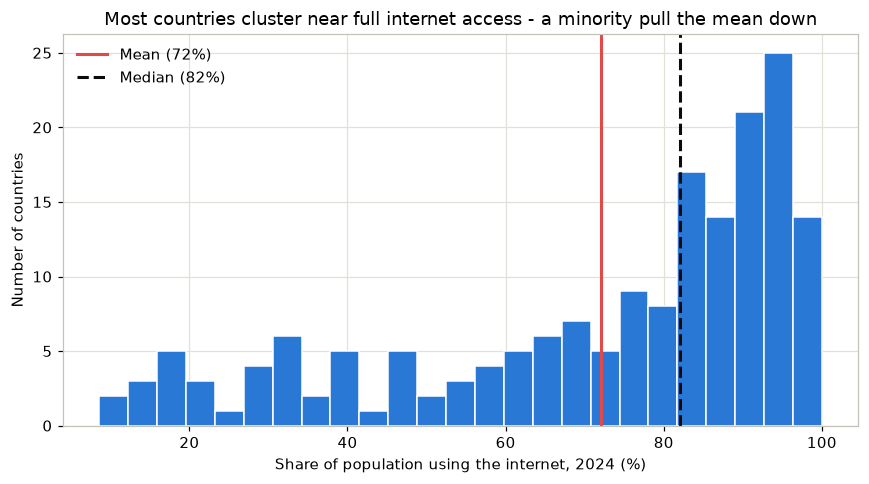

In [7]:
charts_dir = Path("charts")
charts_dir.mkdir(exist_ok=True)

# 1. Histogram - the distribution, left-skewed.
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(latest_year["internet_pct"], bins=25, color=PALETTE["blue"], edgecolor="white")
ax.axvline(latest_year["internet_pct"].mean(), color=PALETTE["red"], linewidth=2,
           label=f"Mean ({latest_year['internet_pct'].mean():.0f}%)")
ax.axvline(latest_year["internet_pct"].median(), color=INK, linestyle="--", linewidth=2,
           label=f"Median ({latest_year['internet_pct'].median():.0f}%)")
ax.set_title("Most countries cluster near full internet access - a minority pull the mean down")
ax.set_xlabel("Share of population using the internet, 2024 (%)")
ax.set_ylabel("Number of countries")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(charts_dir / "01_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

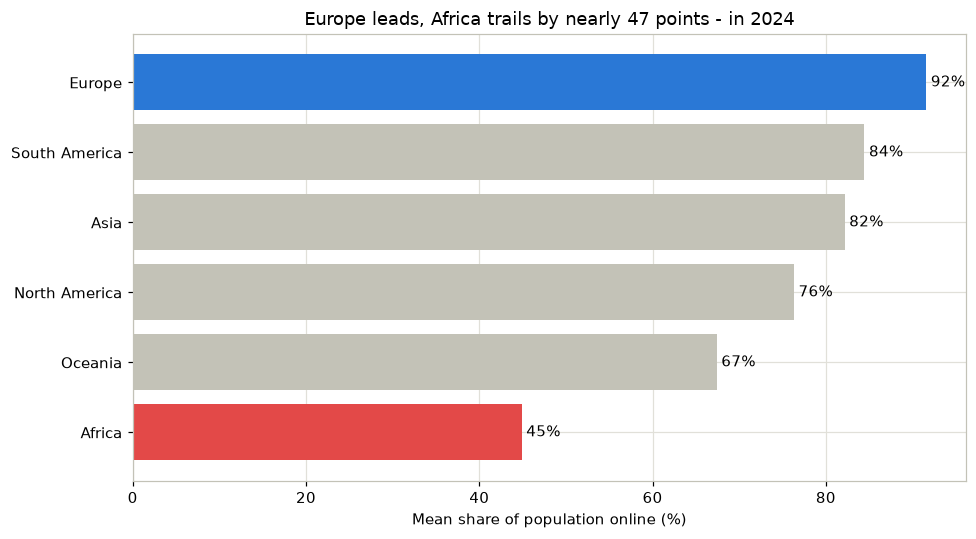

In [8]:
# 2. Bar - regional comparison, sorted, emphasis on the extremes.
fig, ax = plt.subplots(figsize=(9, 5))
colors = [PALETTE["blue"] if r == regional_2024.index[0]
          else (PALETTE["red"] if r == regional_2024.index[-1] else MUTED)
          for r in regional_2024.index]
bars = ax.barh(regional_2024.index[::-1], regional_2024.values[::-1], color=colors[::-1])
ax.bar_label(bars, fmt="%.0f%%", padding=3)
ax.set_title("Europe leads, Africa trails by nearly 47 points - in 2024")
ax.set_xlabel("Mean share of population online (%)")
fig.tight_layout()
fig.savefig(charts_dir / "02_regional_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

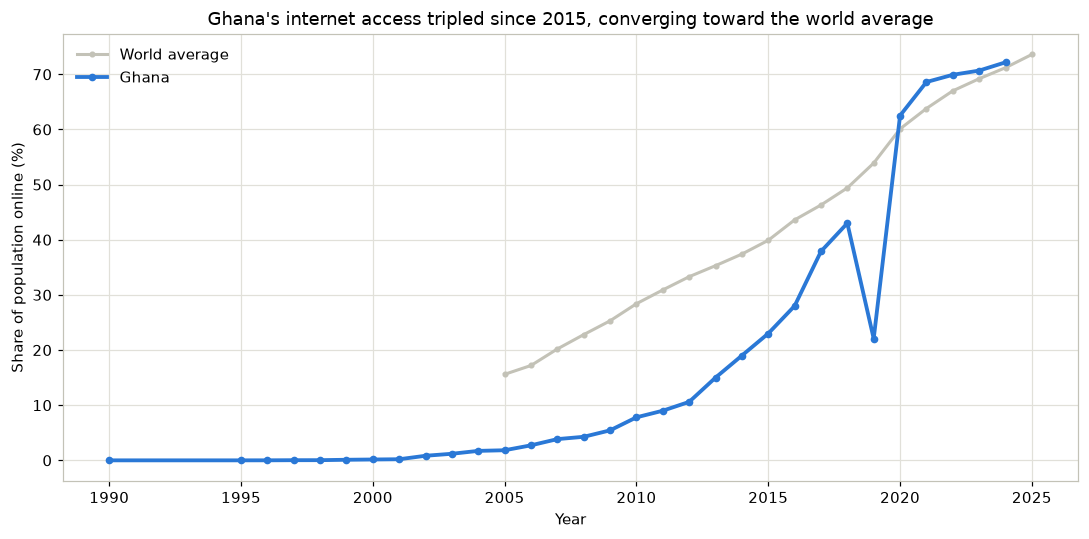

In [9]:
# 3. Line - the global trend, with Ghana overlaid.
fig, ax = plt.subplots(figsize=(10, 5))
years = sorted(internet_raw[internet_raw["entity"] == "World"]["year"].unique())
ax.plot(world_trend.index, world_trend.values, color=MUTED, linewidth=2, marker="o",
        markersize=3, label="World average")
ax.plot(ghana["year"], ghana["internet_pct"], color=PALETTE["blue"], linewidth=2.5,
        marker="o", markersize=4, label="Ghana")
ax.set_title("Ghana's internet access tripled since 2015, converging toward the world average")
ax.set_xlabel("Year")
ax.set_ylabel("Share of population online (%)")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(charts_dir / "03_ghana_vs_world.png", dpi=150, bbox_inches="tight")
plt.show()

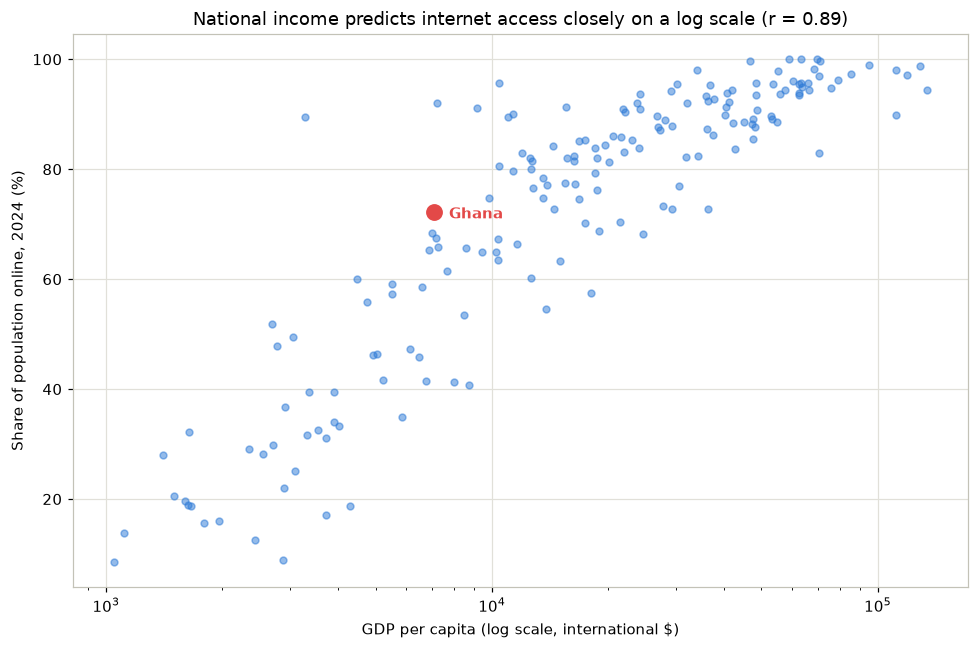

In [10]:
# 4. Scatter, log x-axis - GDP vs internet, the strongest relationship in this dataset.
fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(latest_year["gdp_per_capita"], latest_year["internet_pct"], s=20, alpha=0.5,
           color=PALETTE["blue"])
ghana_row = latest_year[latest_year["entity"] == "Ghana"].iloc[0]
ax.scatter([ghana_row["gdp_per_capita"]], [ghana_row["internet_pct"]], s=100,
           color=PALETTE["red"], zorder=5)
ax.annotate("Ghana", xy=(ghana_row["gdp_per_capita"], ghana_row["internet_pct"]),
            xytext=(10, -4), textcoords="offset points", fontweight="bold", color=PALETTE["red"])
ax.set_xscale("log")
ax.set_title(f"National income predicts internet access closely on a log scale (r = {r_log:.2f})")
ax.set_xlabel("GDP per capita (log scale, international $)")
ax.set_ylabel("Share of population online, 2024 (%)")
fig.tight_layout()
fig.savefig(charts_dir / "04_gdp_vs_internet.png", dpi=150, bbox_inches="tight")
plt.show()

---

## Part 7 - Model

A regression on log(GDP per capita) predicting internet usage - chosen *because* the exploration above showed the log scale fits much better than the raw one, not as a default first move.

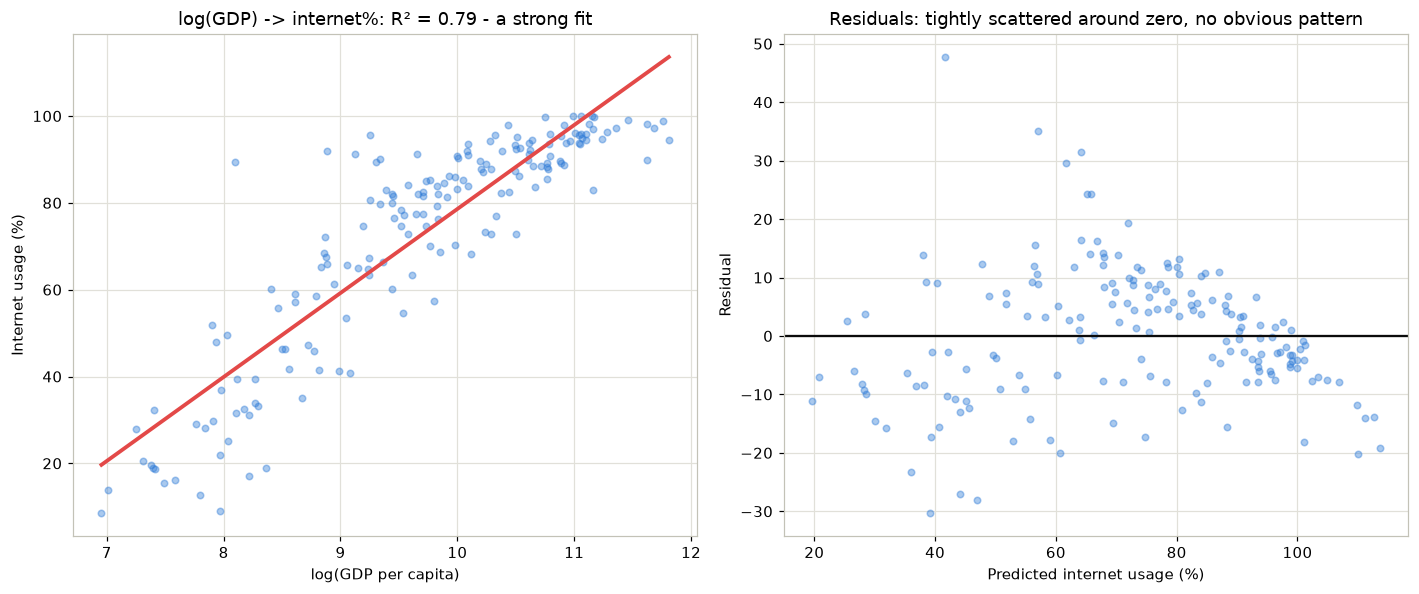

internet_pct = 19.35 x log(gdp_per_capita) + -114.92
R² = 0.790 - log(GDP per capita) alone explains about 79% of the
variation in internet usage across countries - strong enough to describe as a real, usable relationship.


In [11]:
x = np.log(latest_year["gdp_per_capita"].values)
y = latest_year["internet_pct"].values

slope, intercept = np.polyfit(x, y, 1)
predicted = slope * x + intercept
ss_res = ((y - predicted) ** 2).sum()
ss_tot = ((y - y.mean()) ** 2).sum()
r_squared = 1 - ss_res / ss_tot

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(x, y, s=18, alpha=0.4, color=PALETTE["blue"])
x_line = np.linspace(x.min(), x.max(), 50)
axes[0].plot(x_line, slope * x_line + intercept, color=PALETTE["red"], linewidth=2.5)
axes[0].set_title(f"log(GDP) -> internet%: R\u00b2 = {r_squared:.2f} - a strong fit")
axes[0].set_xlabel("log(GDP per capita)")
axes[0].set_ylabel("Internet usage (%)")

residuals = y - predicted
axes[1].scatter(predicted, residuals, s=18, alpha=0.4, color=PALETTE["blue"])
axes[1].axhline(0, color=INK, linewidth=1.5)
axes[1].set_title("Residuals: tightly scattered around zero, no obvious pattern")
axes[1].set_xlabel("Predicted internet usage (%)")
axes[1].set_ylabel("Residual")

fig.tight_layout()
fig.savefig(charts_dir / "05_regression_and_residuals.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"internet_pct = {slope:.2f} x log(gdp_per_capita) + {intercept:.2f}")
print(f"R\u00b2 = {r_squared:.3f} - log(GDP per capita) alone explains about {r_squared*100:.0f}% of the")
print("variation in internet usage across countries - strong enough to describe as a real, usable relationship.")

R² = 0.79 earns the word "predicts" in this section's title in a way that Topic 23b's two examples (0.17 and 0.05) did not. This is the strongest fit across every regression in this topic - worth noticing as a point of contrast: not every relationship found in Topics 20-23 deserved that language, and this one is the exception, not the rule.

---

## Part 8 - Write both reports

In [12]:
wrangle_report = f"""
This dataset combines two Our World in Data files - internet usage and GDP per
capita - covering {merged['entity'].nunique()} countries from {merged['year'].min()}
to {merged['year'].max()}.

Both source files mix individual countries with regional and income-group
aggregates such as "World" and "Africa," sitting in the same column as actual
countries. These aggregates do not carry a standard three-letter country code,
which gave a reliable rule for separating them: any row whose code is not
exactly three letters, or starts with "OWID," was treated as an aggregate and
excluded before any country-level analysis. {before - after} entities were
removed this way, including "World" and every regional grouping - correctly
so, since including them would double-count population figures already
reflected in their member countries.

The two files were joined on country, country code, and year, requiring an
exact one-to-one match - a country-year must appear at most once in each
file, and the merge was set to fail loudly if that stopped being true, rather
than silently duplicating rows. No duplicates were found. Some country-years
present in the internet file have no matching GDP figure and were dropped by
this join; this is expected for countries with incomplete historical economic
records; it was not treated as an error.

No values were estimated or filled in. Where a country lacks data for a given
year, it is simply absent from that year's analysis rather than assigned a
guessed value.
"""

act_report = f"""
Globally, {latest_year['internet_pct'].mean():.0f}% of people now use the
internet - but that average hides a large and persistent gap between regions.

Three findings matter most. First, income predicts access closely: on a
logarithmic income scale, GDP per capita alone explains about
{r_squared*100:.0f}% of the variation in a country's internet usage rate
(R\u00b2 = {r_squared:.2f}) - a strong, usable relationship, not just a loose
correlation. Second, the gap between regions is wide and has not closed:
Europe averages {regional_2024.iloc[0]:.0f}% online against Africa's
{regional_2024['Africa']:.0f}%, a nearly {regional_2024.iloc[0] - regional_2024['Africa']:.0f}-point
gap that mirrors the income gap behind it. Third, Ghana is a genuine success
story within that pattern: internet access rose from {ghana_2015:.0f}% in 2015
to {ghana_2024:.0f}% in 2024 - more than tripling in nine years, and finishing
well above Africa's regional average.

So what: closing the global digital divide is, to a first approximation, an
income problem before it is a technology problem - infrastructure investment
without addressing the underlying income gap is unlikely to close it alone.
Ghana's trajectory is worth studying as a comparator for other sub-Saharan
economies working from a similar starting point in 2015.

Limitations: this analysis uses one cross-sectional year (2024) for the
income-access relationship, so it describes a pattern across countries at one
point in time, not a guarantee that any single country's future income growth
will produce proportional gains in access. GDP and internet access may
reinforce each other rather than one simply causing the other, and this
dataset cannot separate those directions.
"""

Path("wrangle_report.md").write_text(wrangle_report.strip() + "\n")
Path("act_report.md").write_text(act_report.strip() + "\n")
print("Both reports saved.")
print(f"Wrangling report: {len(wrangle_report.split())} words")
print(f"Act report:       {len(act_report.split())} words")

Both reports saved.
Wrangling report: 232 words
Act report:       245 words


---
## Part 9 - Presentation outline

In [13]:
presentation_outline = """
1. Title: Does National Income Predict Internet Access?
2. The headline: 72% of the world is online in 2024, but the gap by region is wide
3. Finding 1: income predicts access closely on a log scale (R2 = 0.79) - chart 04
4. Finding 2: Europe leads at 92%, Africa trails at 45% - chart 02
5. Finding 3: Ghana tripled its internet access since 2015, now above the African average - chart 03
6. So what: this is an income problem before it is a technology problem
7. Limitations: one cross-sectional year for the regression; correlation, not proven causation
8. Questions
"""
Path("presentation_outline.md").write_text(presentation_outline.strip() + "\n")
print("Presentation outline saved.")

Presentation outline saved.


---
## Part 10 - Check this project against the capstone standard

The same check every student's capstone runs - dataset-agnostic, so it works here exactly as it would on any other project.

In [14]:
# Run this cell as it is. It locates and imports project_checks.py, the
# dataset-agnostic structural checker used throughout this topic.
import sys
from pathlib import Path


def find_project_checks_dir():
    candidates = [
        Path.cwd(),
        Path.cwd() / "capstone_project",
        Path.cwd().parent,
        Path.cwd().parent / "capstone_project",
        Path.cwd().parent.parent / "capstone_project",
    ]
    for candidate in candidates:
        if (candidate / "project_checks.py").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find project_checks.py. Looked in: " + ", ".join(str(c) for c in candidates)
    )


project_checks_dir = find_project_checks_dir()
if str(project_checks_dir) not in sys.path:
    sys.path.insert(0, str(project_checks_dir))

import project_checks as pc
print("project_checks.py loaded from:", project_checks_dir)

project_checks.py loaded from: /home/johnny/Projects/itfy-da/capstone_project


In [15]:
import json

results = pc.run_capstone_checks(Path("."), min_chart_count=5)
print(json.dumps(results, indent=2, default=str))

{
  "wrangle_report": {
    "path": "wrangle_report.md",
    "exists": true,
    "word_count": {
      "word_count": 232,
      "min_words": 120,
      "max_words": 500,
      "ok": true
    },
    "forbidden_language": {
      "forbidden_found": [],
      "ok": true
    },
    "ok": true
  },
  "act_report": {
    "path": "act_report.md",
    "exists": true,
    "word_count": {
      "word_count": 245,
      "min_words": 120,
      "max_words": 450,
      "ok": true
    },
    "keywords": {
      "found": {
        "so what": true,
        "limitation": true
      },
      "ok": true
    },
    "numeric_claims": {
      "count": 12,
      "min_count": 5,
      "ok": true
    },
    "ok": true
  },
  "charts": {
    "path": "charts",
    "exists": true,
    "count": 5,
    "files": [
      "01_distribution.png",
      "02_regional_comparison.png",
      "03_ghana_vs_world.png",
      "04_gdp_vs_internet.png",
      "05_regression_and_residuals.png"
    ],
    "min_count": 5,
    "ok": 

If `all_ok` is `True`, this walkthrough meets the same structural bar every student's capstone is held to - proof the bar is achievable, on data nobody pre-built for this course. Remember: this checks *structure*. The reasoning above still had to be correct, the numbers still had to come from real computation, and that part was never something a check cell could verify for you - only a careful reader, which is what your own capstone needs too.